# CNN 실습 ② 다중 분류: 가위바위보 (RPS)

| 항목 | 설정 |
|---|---|
| 데이터 | RPS (가위/바위/보) · 224×224 흑백 복제 · 3종류 + 강화 증강(반전/회전/원근/밝기) |
| 모델 | **ResNet18 전이 학습** (ImageNet 사전학습 → 출력층 3개로 교체) |
| 정답 | 0~2 정수 (paper, rock, scissors) |
| 출력층 | 뉴런 **3개** + **소프트맥스** |


In [78]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 데이터 불러오기
로컬 폴더(`data/rps`)에서 ImageFolder로 불러와요. 학습 2,520장 / 테스트 372장.


In [79]:
transform = transforms.Compose([
    transforms.Lambda(lambda im: im.convert("RGB")),   # RGBA → RGB
    transforms.Resize((300, 300)),                     # 300×300 → 300×300 (정사각 보장)
    transforms.CenterCrop(225),                        # 가장자리 배경 잘라내기 (손이 중앙 75% 영역)
    transforms.Resize((224, 224)),                     # 사전학습 모델 입력 크기
    transforms.Grayscale(num_output_channels=3),       # 컬러 단서 제거(3채널 복제로 사전학습 가중치와 호환)
    # 데이터 증강
    transforms.RandomHorizontalFlip(),                 # 좌우 반전
    transforms.RandomRotation(180),                     # ±25도 회전
    transforms.RandomPerspective(distortion_scale=0.2, p=0.5),      # 약한 원근 왜곡 (촬영 각도 차이)
    transforms.RandomAffine(degrees=0, translate=(0.2, 0.2), scale=(0.5, 1.3)),  # 위치 이동/크기 변화 (손이 작거나 가장자리에 있어도)
    transforms.ColorJitter(brightness=0.3, contrast=0.3),       # 밝기/대비 변화
    transforms.ToTensor(),
])

train_full = datasets.ImageFolder(root="data/rps/train", transform=transform)
test_data  = datasets.ImageFolder(root="data/rps/test/rps-test-set", transform=transform)
classes = train_full.classes
print(classes)
x, y = train_full[0]
print(x.shape, y)   # torch.Size([3, 224, 224]) = 채널 3(흑백 복제) × 224 × 224

['paper', 'rock', 'scissors']
torch.Size([3, 224, 224]) 0


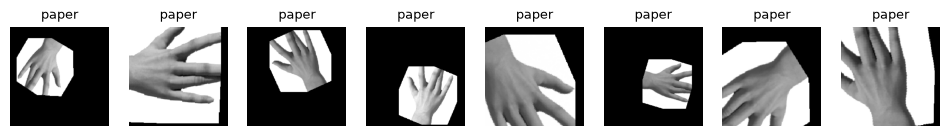

In [80]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    x, y = train_full[i]
    ax.imshow(x[0], cmap="gray"); ax.set_title(classes[y], fontsize=9); ax.axis("off")
plt.show()

## 2. 학습 / 검증 데이터 나누기
학습 2,160장, 검증 360장 (전체 2,520장).


In [81]:
train_data, val_data = random_split(train_full, [2160, 360])
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=128)
test_loader = DataLoader(test_data, batch_size=128)

## 3. 모델 만들기
처음부터 학습하는 대신 **사전학습된 ResNet18**을 가져와 출력층만 바꾸는 **전이 학습**을 해요.
- 사전학습 모델은 이미 다양한 물체의 모양/텍스처를 학습해서 손 형태 일반화에 유리해요.
- `CrossEntropyLoss`가 소프트맥스를 포함하므로 출력층 뒤에 소프트맥스는 없어요.


In [82]:
from torchvision.models import resnet18, ResNet18_Weights

# 전이 학습: ImageNet으로 사전학습된 ResNet18을 가져온 뒤 출력층만 교체
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 3)   # 출력 3개 (가위/바위/보)
model = model.to(device)

# 출력 확인
x = torch.zeros(1, 3, 224, 224).to(device)
with torch.no_grad():
    out = model(x)
print("출력 shape:", out.shape)
print("학습할 파라미터 수:", sum(p.numel() for p in model.parameters()))

출력 shape: torch.Size([1, 3])
학습할 파라미터 수: 11178051


## 4. 손실 함수와 옵티마이저

In [ ]:
loss_fn = nn.CrossEntropyLoss()                         # 소프트맥스 + 크로스엔트로피
optimizer = torch.optim.Adam(model.parameters(), lr=0.0003)   # 사전학습 가중치를 크게 흔들지 않도록 낮은 학습률

def predict(out):
    return out.argmax(dim=1)                             # 가장 큰 값의 클래스 번호

EPOCHS = 20
SAVE_PATH = "best_rps.pt"

## 5. 학습

In [84]:
def evaluate(loader):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (predict(out) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        out = model(X)               # 1. 순전파
        loss = loss_fn(out, y)       # 2. 손실 계산
        optimizer.zero_grad()
        loss.backward()              # 3. 역전파 (커널과 FC층의 기울기 계산)
        optimizer.step()             # 4. 업데이트 (경사하강법 계열: Adam)

        total_loss += loss.item() * len(y)
        correct += (predict(out) == y).sum().item()
        n += len(y)

    val_loss, val_acc = evaluate(val_loader)
    history.append((total_loss / n, correct / n, val_loss, val_acc))
    print(f"epoch {epoch:2d} | train loss {total_loss/n:.4f} acc {correct/n:.3f} | val loss {val_loss:.4f} acc {val_acc:.3f}")

    if val_loss < best_val_loss:     # 검증 loss가 가장 낮을 때의 w 저장
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)

epoch  1 | train loss 0.2429 acc 0.908 | val loss 0.3414 acc 0.897
epoch  2 | train loss 0.0963 acc 0.965 | val loss 0.0363 acc 0.986
epoch  3 | train loss 0.0415 acc 0.985 | val loss 0.0230 acc 0.994
epoch  4 | train loss 0.0470 acc 0.987 | val loss 0.0546 acc 0.983
epoch  5 | train loss 0.0435 acc 0.988 | val loss 0.0487 acc 0.983
epoch  6 | train loss 0.0308 acc 0.990 | val loss 0.0344 acc 0.992
epoch  7 | train loss 0.0360 acc 0.988 | val loss 0.0376 acc 0.989
epoch  8 | train loss 0.0291 acc 0.991 | val loss 0.0414 acc 0.983
epoch  9 | train loss 0.0343 acc 0.988 | val loss 0.0508 acc 0.981
epoch 10 | train loss 0.0403 acc 0.986 | val loss 0.0484 acc 0.978
epoch 11 | train loss 0.0316 acc 0.990 | val loss 0.0098 acc 0.997
epoch 12 | train loss 0.0280 acc 0.992 | val loss 0.0241 acc 0.989
epoch 13 | train loss 0.0322 acc 0.989 | val loss 0.0612 acc 0.989
epoch 14 | train loss 0.0256 acc 0.991 | val loss 0.0259 acc 0.989
epoch 15 | train loss 0.0188 acc 0.994 | val loss 0.0455 acc 0

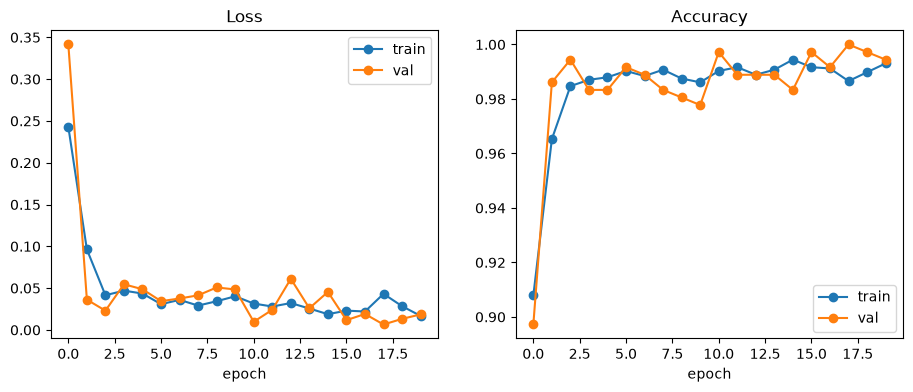

In [85]:
import matplotlib.pyplot as plt
h = list(zip(*history))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(h[0], "o-", label="train"); ax1.plot(h[2], "o-", label="val"); ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(h[1], "o-", label="train"); ax2.plot(h[3], "o-", label="val"); ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()
plt.show()

## 6. 테스트

test loss 0.1784, test acc 0.927


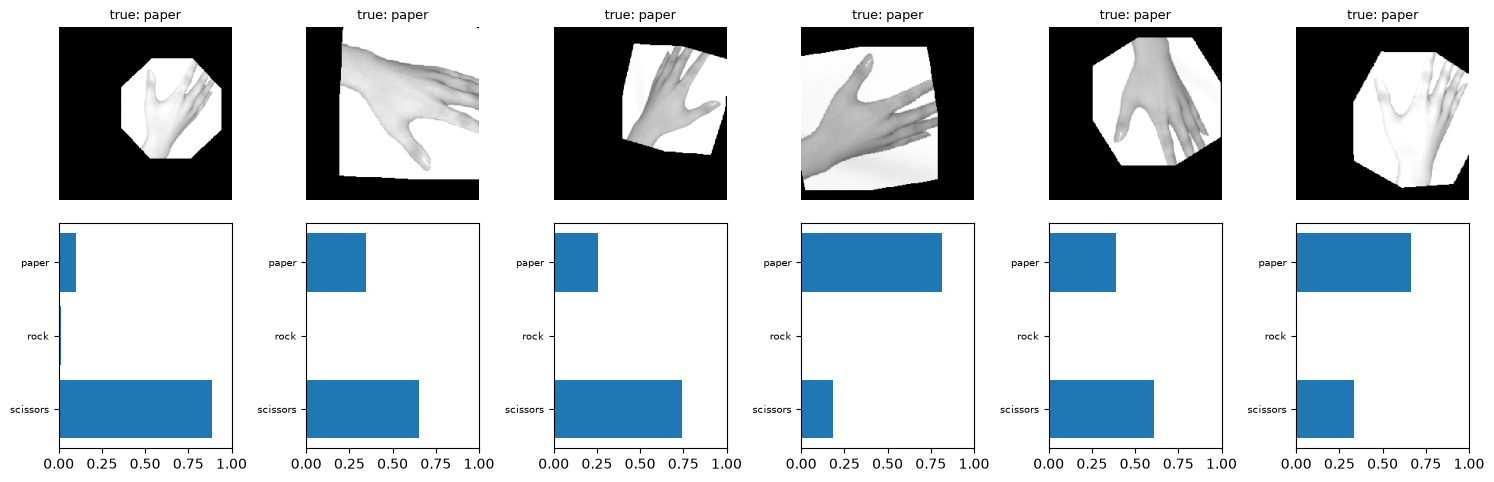

In [86]:
model.load_state_dict(torch.load(SAVE_PATH))
test_loss, test_acc = evaluate(test_loader)
print(f"test loss {test_loss:.4f}, test acc {test_acc:.3f}")

model.eval()
X, y = next(iter(DataLoader(test_data, batch_size=6)))
with torch.no_grad():
    prob = torch.softmax(model(X.to(device)), dim=1).cpu()    # 3개 클래스 확률 (합 = 1)

fig, axes = plt.subplots(2, 6, figsize=(15, 5), gridspec_kw={"height_ratios": [1, 1.2]})
for k in range(6):
    axes[0, k].imshow(X[k][0], cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"true: {classes[y[k]]}", fontsize=9)
    axes[1, k].barh(range(3), prob[k]); axes[1, k].set_yticks(range(3)); axes[1, k].set_yticklabels(classes, fontsize=7)
    axes[1, k].invert_yaxis(); axes[1, k].set_xlim(0, 1)
plt.tight_layout(); plt.show()

In [87]:
# 어떤 클래스끼리 많이 헷갈렸을까? (혼동 행렬)
n_cls = len(classes)
conf = torch.zeros(n_cls, n_cls, dtype=torch.long)
with torch.no_grad():
    for X, y in test_loader:
        p = model(X.to(device)).argmax(1).cpu()
        for a, b in zip(y, p):
            conf[a, b] += 1
pairs = [(conf[i, j].item(), classes[i], classes[j]) for i in range(n_cls) for j in range(n_cls) if i != j]
for cnt, a, b in sorted(pairs, reverse=True)[:5]:
    print(f"정답 {a:12s} → 예측 {b:12s}: {cnt}개")

정답 paper        → 예측 scissors    : 15개
정답 paper        → 예측 rock        : 9개
정답 scissors     → 예측 rock        : 2개
정답 scissors     → 예측 paper       : 0개
정답 rock         → 예측 scissors    : 0개


## 7. 더 해 보기
- `EPOCHS`를 10으로 늘리면 정확도가 얼마나 오를까요? 검증 loss도 같이 보세요.
- 커널 크기를 5로 바꿔 보세요 (`kernel_size=5, padding=2`). 출력 크기는 그대로일까요?
- 실습 ①과 비교해 보세요: 출력 뉴런 수, 손실 함수, `predict` 함수가 어떻게 달라졌나요?

## 8. 최종 테스트 (validation)
개발 과정에 한 번도 안 쓴 폴더(`data/rps/validation`)로 마지막 평가를 해요.


In [88]:
final_data = datasets.ImageFolder(root="data/rps/validation", transform=transform)
final_loader = DataLoader(final_data, batch_size=32)
print("validation 클래스:", final_data.classes, "| 이미지 수:", len(final_data))

model.load_state_dict(torch.load(SAVE_PATH))   # 검증 loss가 가장 낮았던 가중치 불러오기
final_loss, final_acc = evaluate(final_loader)
print(f"최종 테스트 loss {final_loss:.4f}, 정확도 {final_acc:.3f}")


validation 클래스: ['paper', 'rock', 'sissor'] | 이미지 수: 17
최종 테스트 loss 2.5879, 정확도 0.588


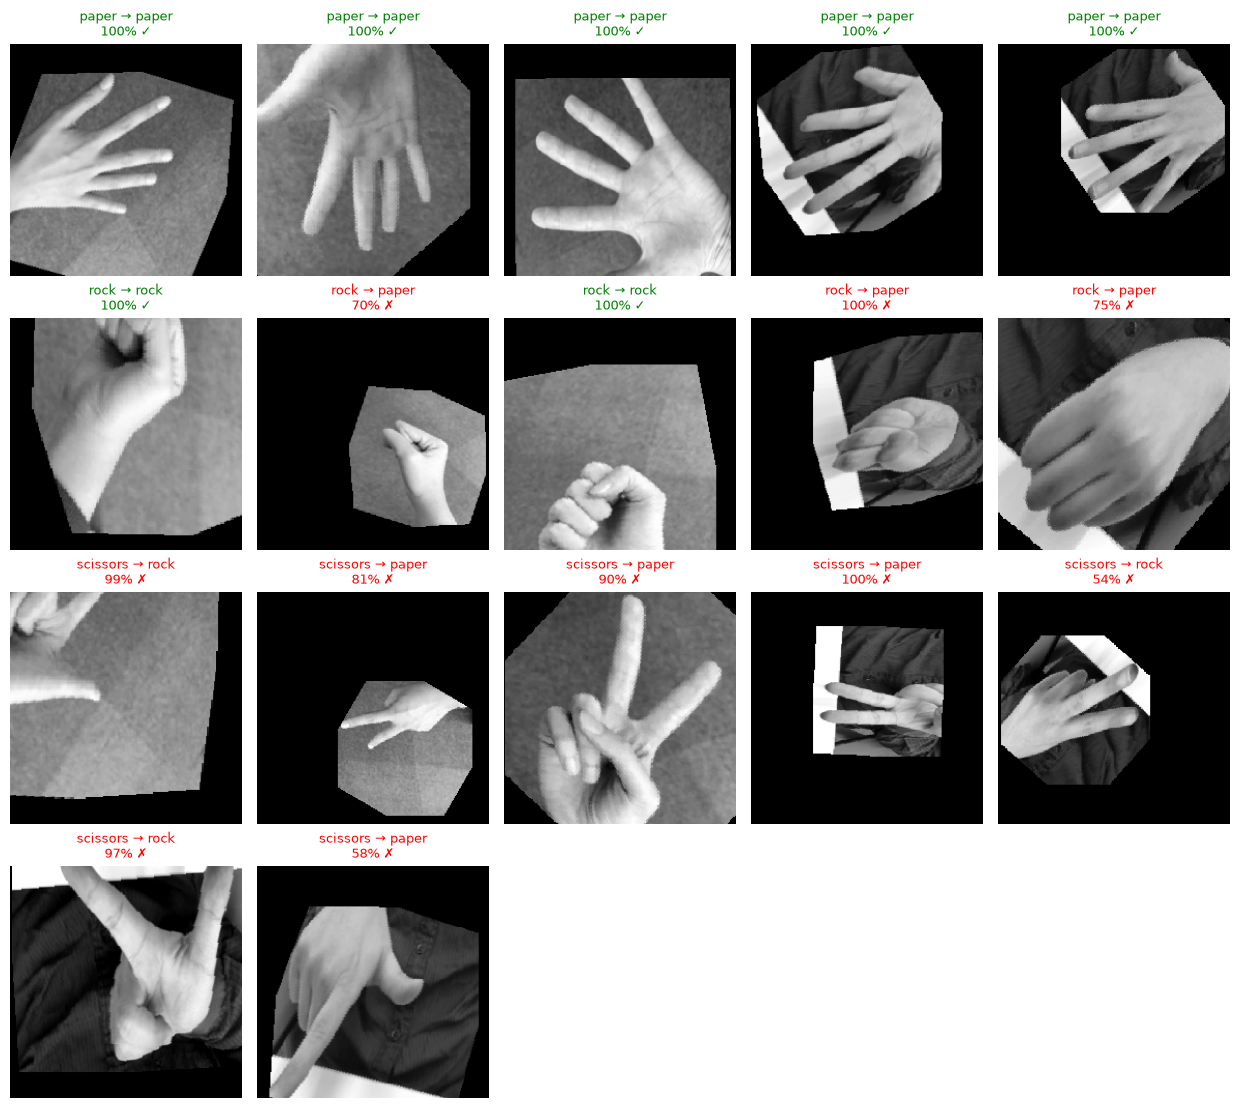

In [89]:
# validation 이미지 하나씩: 이미지 + 판정 결과(클래스별 확률) 보기
model.eval()
n_img = len(final_data)
cols = 5
rows = (n_img + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.8))
axes = axes.flatten()
with torch.no_grad():
    for i, (x, y) in enumerate(final_data):
        out = model(x.unsqueeze(0).to(device))
        prob = torch.softmax(out, dim=1).cpu()[0]
        pred = prob.argmax()
        true = classes[y]
        ok = (pred.item() == y)
        axes[i].imshow(x[0], cmap="gray")
        axes[i].set_title(f"{true} → {classes[pred]}\n{prob[pred]:.0%} {'✓' if ok else '✗'}",
                          color=("green" if ok else "red"), fontsize=9)
        axes[i].axis("off")
for ax in axes[n_img:]:
    ax.axis("off")
plt.tight_layout(); plt.show()
